# Barcode Plot (Rug Plot)

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Draws each observation as a thin vertical tick on a line. It is a minimal, high-resolution distribution display that also works well for placing one item among the rest.

## When to use

- Show exactly where individual values fall, for example to highlight one country among all of them
- Show a compact distribution strip for dashboards and tables
- Add a margin to a density or scatter plot

## Avoid when

- There are many duplicate or close values (ticks overlap and hide counts)
- The audience needs the shape (add a density curve)

## Alternatives

- Dot strip plot
- Histogram
- Beeswarm

## Design tips

- Use thin, semi-transparent ticks so clusters read darker than gaps
- Make the highlighted item thicker and coloured, and keep everything else gray
- Put one strip per date or group on a shared x-axis so positions can be compared

## Example

Unemployment rate of 50 US-like states on three dates, highlighting one state (simulated).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(41)
dates = ["Jan 2020", "Apr 2020", "Jan 2022"]
centers = [3.6, 13.0, 4.2]
spreads = [0.8, 3.5, 1.0]
df = pd.concat([pd.DataFrame({"date": d, "state": [f"S{i:02d}" for i in range(50)],
                              "rate": rng.normal(c, s, 50).clip(1.5)})
                for d, c, s in zip(dates, centers, spreads)], ignore_index=True)
focus = "S07"
df[df["state"] == focus]

,date,state,rate
7,Jan 2020,S07,2.663346
57,Apr 2020,S07,15.839486
107,Jan 2022,S07,3.870322


### Plot

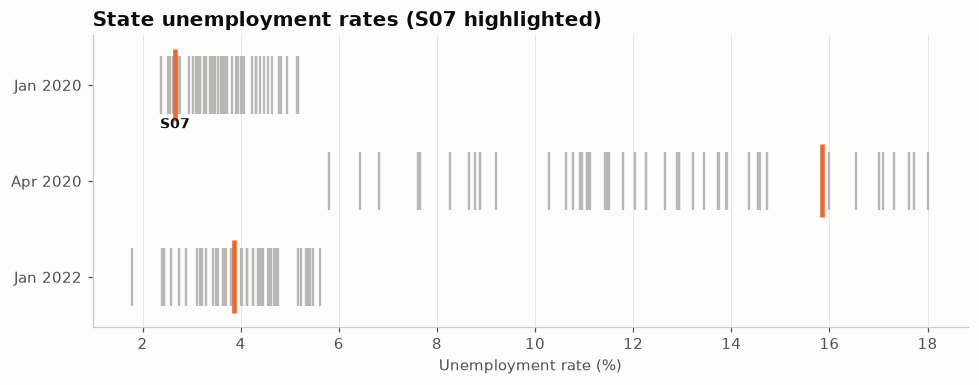

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for y, d in enumerate(dates):
    g = df[df["date"] == d]
    ax.vlines(g["rate"], y - 0.3, y + 0.3, color=GRAY, linewidth=1.5)
    f = g[g["state"] == focus]["rate"].iloc[0]
    ax.vlines(f, y - 0.38, y + 0.38, color=PALETTE[1], linewidth=3)
    if y == 0:
        ax.text(f, y + 0.45, focus, ha="center", fontsize=9, color="#0b0b0b", weight="bold")
ax.set_yticks(range(len(dates)), dates)
ax.invert_yaxis()
ax.set_xlabel("Unemployment rate (%)")
ax.set_title(f"State unemployment rates ({focus} highlighted)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Each gray tick is one state, and the orange tick is S07. In April 2020 every state jumped and the spread widened from about 2–5% to about 6–18%. S07 went from below the median (2.7%) to the 9th-highest rate (15.8%), then returned to the middle of the pack (3.9%) by January 2022.

---
Standalone script: [`barcode_plot.py`](barcode_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)